In [1]:
import pandas as pd
import os
import textdistance
import seaborn as sns
import matplotlib.pyplot as plt
from unidecode import unidecode
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import re

In [2]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /home/corey/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/corey/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
# Set the directory where your CSV files are located
folder_path = '../data/vivino/similarity_href_subsets'

# Get a list of all CSV files in the folder
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

# Initialize an empty list to store individual dataframes
dfs = []

# Loop through each CSV file, read it into a dataframe, and append it to the list
for file in csv_files:
    file_path = os.path.join(folder_path, file)
    df = pd.read_csv(file_path)
    dfs.append(df)

# Concatenate all dataframes into one
matching_df = pd.concat(dfs, ignore_index=True)

In [5]:
# Drop rows where "cleanskin" appears as a substring in either name column, ignoring case
#matching_df = matching_df[~(matching_df['dm_product_name'].str.contains('cleanskin', case=False) | matching_df['vivino_product_name'].str.contains('cleanskin', case=False))].reset_index(drop=True)

In [6]:
#matching_df = matching_df[matching_df["dm_brand_name"] == "Sit Stay Society"]

In [7]:
matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715
4,Illuminati,ilico Montepulciano d'Abruzzo,https://www.danmurphys.com.au/product/DM_91724...,Illuminati Ilico,https://www.vivino.com/AU/en/wines/1469260
...,...,...,...,...,...
6052,Elephant In The Room,Tempranillo,https://www.danmurphys.com.au/product/DM_86526...,Elephant In The Room Titanic Tempranillo,https://www.vivino.com/AU/en/wines/165182546
6053,Brown Brothers,Winemakers Series Tempranillo Graciano,https://www.danmurphys.com.au/product/DM_86491...,Brown Brothers Winemaker’S Series Tempranillo ...,https://www.vivino.com/AU/en/wines/165373677
6054,Noble Fellows,Colonel Kiwi Marlborough Pinot Noir,https://www.danmurphys.com.au/product/DM_86484...,Noble Fellows Colonel Kiwi Pinot Noir,https://www.vivino.com/AU/en/wines/161072244
6055,Distant South,Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_86462...,Distant South Pinot Noir,https://www.vivino.com/AU/en/wines/160780353


### Calculate similarity

In [8]:
matching_df = matching_df[matching_df['vivino_product_name'].notna()].reset_index(drop=True)
matching_df[matching_df["vivino_product_name"].isna()]

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href


In [9]:
def remove_punctuation(text):
    return re.sub(r'[^\w\s]', '', text)

def remove_spaces(text):
    return re.sub(r'\s+', '', text)
    
def calculate_brand_name_presence(row):
    dm_brand_name = remove_spaces(remove_punctuation(unidecode(row["dm_brand_name"].lower())))
    vivino_product_name = remove_spaces(remove_punctuation(unidecode(row["vivino_product_name"].lower())))
    if dm_brand_name in vivino_product_name:
        return True
    else:
        return False

def calculate_brand_name_presence_tokenize(row):
    stop_words = set(stopwords.words('english'))
    dm_brand_name = (unidecode(row["dm_brand_name"].lower()))
    dm_brand_tokens = word_tokenize(dm_brand_name)
    vivino_product_name = (unidecode(row["vivino_product_name"].lower()))
    vivino_product_tokens = word_tokenize(vivino_product_name)
    
    # Remove stop words and non-alphanumeric tokens
    dm_brand_tokens = [word for word in dm_brand_tokens if word.isalnum() and word not in stop_words]
    vivino_product_tokens = [word for word in vivino_product_tokens if word.isalnum() and word not in stop_words]

    # Convert lists to sets
    dm_brand_set = set(dm_brand_tokens)
    vivino_product_set = set(vivino_product_tokens)
    intersection = dm_brand_set.intersection(vivino_product_set)

    return intersection == dm_brand_set

matching_df['brand_present'] = matching_df.apply(calculate_brand_name_presence, axis=1)

In [10]:
percentage_unbranded = (len(matching_df[matching_df["brand_present"] == False]) / len(matching_df))
print("percentage of vivino results missing brand:", percentage_unbranded)
matching_df[matching_df["brand_present"] == False]

percentage of vivino results missing brand: 0.2125516102394715


,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present
12,Jim Barry,Forger Shiraz 1.5L Magnum 2020,https://www.danmurphys.com.au/product/DM_23820...,Volpaia Castello Di Volpaia Chianti Classico R...,https://www.vivino.com/AU/en/wines/4912573,False
15,Seven Eves,Wholebunch Syrah,https://www.danmurphys.com.au/product/DM_23798...,Thirty Seven Syrah,https://www.vivino.com/AU/en/wines/4885709,False
45,Yallingup Estate,The Coveted Shiraz 2020,https://www.danmurphys.com.au/product/DM_19646...,Irvine The Estate Shiraz 2020,https://www.vivino.com/AU/en/wines/162960507,False
47,In Esperado,Garnacha,https://www.danmurphys.com.au/product/DM_19258...,Honoro Vera Garnacha,https://www.vivino.com/AU/en/wines/1778254,False
61,Chateau Figeac,2018,https://www.danmurphys.com.au/product/DM_18346...,Château Gravier Figeac Saint-Émilion 2018,https://www.vivino.com/AU/en/wines/162685574,False
...,...,...,...,...,...,...
5976,Pavelot Frères,Savigny-Les-Beaune 2014,https://www.danmurphys.com.au/product/DM_56710...,Levert Frères Savigny-Lès-Beaune 2014,https://www.vivino.com/AU/en/wines/22235744,False
5985,Kaesler Wines,Old Bastard Shiraz 2014 750mL,https://www.danmurphys.com.au/product/DM_55877...,Kaesler Old Bastard Shiraz,https://www.vivino.com/AU/en/wines/4718643,False
6011,Gitanos Errantes,Mendoza Malbec Del Pueblo,https://www.danmurphys.com.au/product/DM_89274...,Chaffey Bros Wine Co. Malbec Del Pueblo,https://www.vivino.com/AU/en/wines/111789838,False
6031,Little Giant,Red Blend 375mL,https://www.danmurphys.com.au/product/DM_87743...,Little Birdwood Red Blend,https://www.vivino.com/AU/en/wines/3491504,False


In [11]:
matching_df = matching_df[matching_df["brand_present"] == True].reset_index(drop=True)

In [12]:
debug = False

def debug_print(*args, **kwargs):
    if debug:
        print(*args, **kwargs)

def calculate_brand_name_presence(row):
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    if dm_brand_name in vivino_product_name:
        return True
    else:
        return False

def remove_substring_and_strip(text, substring):
    # Remove the substring
    new_text = text.replace(substring, '')
    # Strip leading and trailing spaces
    new_text = new_text.strip()
    return new_text

# Function to calculate normalized Levenshtein similarity
def calculate_levenshtein_similarity(row):
    # remove brand from vivino product name
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    dm_product_name = remove_punctuation(unidecode(row["dm_product_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["vivino_product_name"].lower()))
    vivino_product_name = remove_substring_and_strip(vivino_product_name, dm_brand_name)
    
    #print("calculating levenshtein_similarity:", dm_product_name, "---", vivino_product_name)
    return textdistance.levenshtein.normalized_similarity(dm_product_name, vivino_product_name)

def calculate_jaccard_similarity(row):
    stop_words = set(stopwords.words('english'))

    # remove brand from vivino product name
    debug_print("############################################")
    debug_print("Removing brand from vivino product name...")
    debug_print("vivino_product_before:", row["vivino_product_name"])
    dm_brand_name = remove_punctuation(unidecode(row["dm_brand_name"].lower()))
    vivino_product_name = remove_punctuation(unidecode(row["vivino_product_name"].lower()))
    vivino_product_name = remove_substring_and_strip(vivino_product_name, dm_brand_name)
    debug_print("dm_brand_name:", dm_brand_name)
    debug_print("vivino_product_name_after:", vivino_product_name)
    debug_print()
    
    # Tokenize the product names into words and convert to lower case
    debug_print("Tokenizing the product names into words and convert to lower case...")
    dm_product_name = remove_punctuation(unidecode(row['dm_product_name'].lower()))
    dm_tokens = word_tokenize(dm_product_name)
    vivino_tokens = word_tokenize(vivino_product_name)
    debug_print("calculating jaccard_similarity:", dm_product_name, "---", vivino_product_name)
    print()
    
    # Remove stop words and non-alphanumeric tokens
    dm_tokens = [word for word in dm_tokens if word.isalnum() and word not in stop_words]
    vivino_tokens = [word for word in vivino_tokens if word.isalnum() and word not in stop_words]
    
    # Convert lists to sets
    dm_set = set(dm_tokens)
    vivino_set = set(vivino_tokens)
    
    # Calculate Jaccard similarity
    intersection = dm_set.intersection(vivino_set)
    debug_print("intersection:", intersection)
    union = dm_set.union(vivino_set)
    debug_print("union:", union)
    
    if not union:
        return 0.0  # Handle the case when both sets are empty
    
    jaccard_similarity = len(intersection) / len(union)

    debug_print("jaccard_similarity:", jaccard_similarity)
    debug_print("\n\n")
    return jaccard_similarity

# Apply the function to each row
matching_df['levenshtein_similarity'] = matching_df.apply(calculate_levenshtein_similarity, axis=1)
matching_df['jaccard_similarity'] = matching_df.apply(calculate_jaccard_similarity, axis=1)

In [13]:
matching_df.head(10)

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758,True,1.000000,1.000000
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True,0.466667,0.500000
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True,0.416667,0.500000
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True,0.400000,0.500000
4,Illuminati,ilico Montepulciano d'Abruzzo,https://www.danmurphys.com.au/product/DM_91724...,Illuminati Ilico,https://www.vivino.com/AU/en/wines/1469260,True,0.178571,0.333333
5,Shingleback,D Block McLaren Vale Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91710...,Shingleback D Block Reserve Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/4731697,True,0.769231,0.500000
6,Philip Shaw,No.17 Merlot Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91674...,Philip Shaw Wrangles Cabernet Sauvignon - Merlot,https://www.vivino.com/AU/en/wines/155194174,True,0.485714,0.600000
7,Tapanappa,Whalebone Vineyard Cabernet Shiraz,https://www.danmurphys.com.au/product/DM_91671...,Tapanappa Whalebone Vineyard Cabernet - Shiraz,https://www.vivino.com/AU/en/wines/2600361,True,0.971429,1.000000
8,Domaine,Simha Rama Pinot Noir,https://www.danmurphys.com.au/product/DM_23945...,Domaine Simha Nature Pinot Noir,https://www.vivino.com/AU/en/wines/157307722,True,0.782609,0.600000
9,Domaine Simha,Nature Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_23863...,Domaine Simha Nature Pinot Noir,https://www.vivino.com/AU/en/wines/157307722,True,0.653846,0.750000


### Assess Levenshtein similarity results

In [14]:
print(f"mean of similarity: {matching_df.levenshtein_similarity.mean()}")
print(f"standard deviation of similarity: {matching_df.levenshtein_similarity.std()}")

mean of similarity: 0.6837664147656
standard deviation of similarity: 0.2697662294969368


/home/corey/anaconda3/envs/winevalet_env1/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


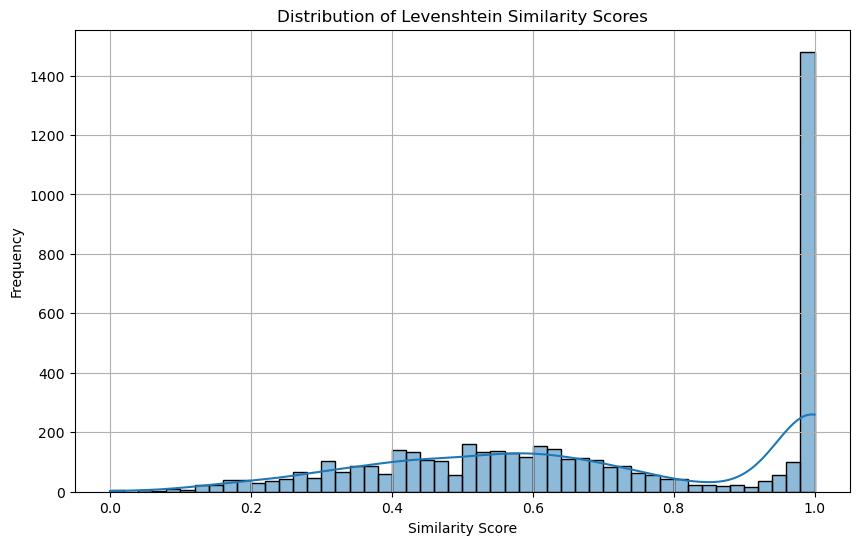

In [15]:
# Plotting the distribution using Seaborn
plt.figure(figsize=(10, 6))
sns.histplot(matching_df['levenshtein_similarity'], bins=50, kde=True)
plt.title('Distribution of Levenshtein Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [16]:
cut_offs = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9]

for cut_off in cut_offs:
    percentage_above = len(matching_df[matching_df["levenshtein_similarity"] > cut_off]) / len(matching_df)
    print(f"percentage of rows above {cut_off}: {percentage_above}")

percentage of rows above 0.5: 0.7019714765100671
percentage of rows above 0.55: 0.6453439597315436
percentage of rows above 0.6: 0.5721476510067114
percentage of rows above 0.65: 0.506501677852349
percentage of rows above 0.7: 0.44945469798657717
percentage of rows above 0.75: 0.40310402684563756
percentage of rows above 0.8: 0.37793624161073824
percentage of rows above 0.9: 0.35192953020134227


In [17]:
min_matching_df = matching_df[(matching_df["levenshtein_similarity"] >= 0.7) & (matching_df["levenshtein_similarity"] < 0.75)]
min_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
20,Voyager Estate,Cabernet Sauvignon 2015,https://www.danmurphys.com.au/product/DM_23468...,Voyager Estate Cabernet Sauvignon - Merlot 2015,https://www.vivino.com/AU/en/wines/141673583,True,0.741935,0.750000
81,Parker Coonawarra Estate,95 Block Cabernet Sauvignon 2019,https://www.danmurphys.com.au/product/DM_16725...,Parker Coonawarra Estate Terra Rossa Cabernet ...,https://www.vivino.com/AU/en/wines/160153464,True,0.714286,0.428571
170,Grant Burge,Nebu Barossa Cabernet Shiraz 2017,https://www.danmurphys.com.au/product/DM_11068...,Grant Burge Nebu Cabernet - Shiraz 2017,https://www.vivino.com/AU/en/wines/158922466,True,0.727273,0.800000
173,Henschke,Mount Edelstone Shiraz 2018,https://www.danmurphys.com.au/product/DM_10845...,Henschke Mount Edelstone 2018,https://www.vivino.com/AU/en/wines/177366123,True,0.740741,0.750000
224,Noble Fellows,Mary Bo Peep Marlborough Sauvignon Blanc,https://www.danmurphys.com.au/product/DM_86479...,Noble Fellows Mary Bo Peep Sauvignon Blanc,https://www.vivino.com/AU/en/wines/160426767,True,0.700000,0.833333
...,...,...,...,...,...,...,...,...
4680,Vasse Felix,Tom Cullity Cabernet Malbec,https://www.danmurphys.com.au/product/DM_60512...,Vasse Felix Tom Cullity Cabernet Sauvignon - M...,https://www.vivino.com/AU/en/wines/148766977,True,0.710526,0.800000
4711,Frankland Estate,Isolation Ridge Shiraz,https://www.danmurphys.com.au/product/DM_90106...,Frankland Estate Isolation Ridge Vineyard Shiraz,https://www.vivino.com/AU/en/wines/4343001,True,0.709677,0.750000
4717,Leeuwin Estate,Prelude Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_89665...,Leeuwin Estate Prelude Vineyards Cabernet Sauv...,https://www.vivino.com/AU/en/wines/2943692,True,0.722222,0.750000
4744,Hear No Evil,Organic Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_87812...,No Evil Hear No Evil Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/171027897,True,0.740741,0.500000


In [18]:
for i, row in min_matching_df.iterrows():
    print(f"i={i} \"{row.dm_brand_name} {row.dm_product_name}\"   ---   \"{row.vivino_product_name}   ---   {row.levenshtein_similarity}\"\n")

i=20 "Voyager Estate Cabernet Sauvignon 2015"   ---   "Voyager Estate Cabernet Sauvignon - Merlot 2015   ---   0.7419354838709677"

i=81 "Parker Coonawarra Estate 95 Block Cabernet Sauvignon 2019"   ---   "Parker Coonawarra Estate Terra Rossa Cabernet Sauvignon 2019   ---   0.7142857142857143"

i=170 "Grant Burge Nebu Barossa Cabernet Shiraz 2017"   ---   "Grant Burge Nebu Cabernet - Shiraz 2017   ---   0.7272727272727273"

i=173 "Henschke Mount Edelstone Shiraz 2018"   ---   "Henschke Mount Edelstone 2018   ---   0.7407407407407407"

i=224 "Noble Fellows Mary Bo Peep Marlborough Sauvignon Blanc"   ---   "Noble Fellows Mary Bo Peep Sauvignon Blanc   ---   0.7"

i=357 "Peter Lehmann Botrytis Semillon 375mL"   ---   "Peter Lehmann Botrytis Semillon   ---   0.7391304347826086"

i=378 "Villa Maria Marlborough Cellar Selection Sauvignon Blanc"   ---   "Villa Maria Cellar Selection Sauvignon Blanc   ---   0.7272727272727273"

i=387 "Dopff Au Moulin Riesling Grand Cru Schoenenbourg"   ---   "

In [19]:
"""
i = 1110
print(min_matching_df.loc[i].dm_full_product_name)
print(min_matching_df.loc[i].dm_href)
print(min_matching_df.loc[i].vivino_product_name)
print(min_matching_df.loc[i].vivino_href)
print(min_matching_df.loc[i].levenshtein_similarity)
print(min_matching_df.loc[i].jaccard_similarity)
"""

'\ni = 1110\nprint(min_matching_df.loc[i].dm_full_product_name)\nprint(min_matching_df.loc[i].dm_href)\nprint(min_matching_df.loc[i].vivino_product_name)\nprint(min_matching_df.loc[i].vivino_href)\nprint(min_matching_df.loc[i].levenshtein_similarity)\nprint(min_matching_df.loc[i].jaccard_similarity)\n'

### Assess Jaccard similarity results

In [20]:
print(f"mean of similarity: {matching_df.jaccard_similarity.mean()}")
print(f"standard deviation of similarity: {matching_df.jaccard_similarity.std()}")

mean of similarity: 0.6963799777427084
standard deviation of similarity: 0.2717241643128746


/home/corey/anaconda3/envs/winevalet_env1/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


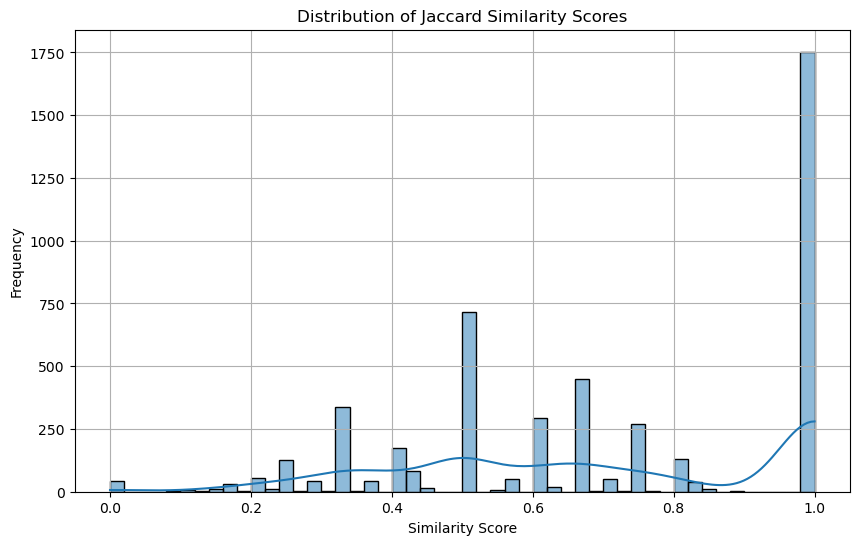

In [21]:
# Plotting the distribution using Seaborn
plt.figure(figsize=(10, 6))
sns.histplot(matching_df['jaccard_similarity'], bins=50, kde=True)
plt.title('Distribution of Jaccard Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [22]:
cut_offs = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9]

for cut_off in cut_offs:
    percentage_above = len(matching_df[matching_df["jaccard_similarity"] > cut_off]) / len(matching_df)
    print(f"percentage of rows above {cut_off}: {percentage_above}")

percentage of rows above 0.5: 0.6442953020134228
percentage of rows above 0.55: 0.6442953020134228
percentage of rows above 0.6: 0.5708892617449665
percentage of rows above 0.65: 0.5671140939597316
percentage of rows above 0.7: 0.47273489932885904
percentage of rows above 0.75: 0.40583053691275167
percentage of rows above 0.8: 0.37856543624161076
percentage of rows above 0.9: 0.36765939597315433


In [23]:
min_matching_df = matching_df[(matching_df["jaccard_similarity"] >= 0.5) & (matching_df["jaccard_similarity"] < 0.6)]
min_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True,0.466667,0.5
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True,0.416667,0.5
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True,0.400000,0.5
5,Shingleback,D Block McLaren Vale Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91710...,Shingleback D Block Reserve Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/4731697,True,0.769231,0.5
18,Grant Burge,Holy Trinity GSM 2020,https://www.danmurphys.com.au/product/DM_23574...,Grant Burge The Holy Trinity Red Blend 2020,https://www.vivino.com/AU/en/wines/170293579,True,0.580645,0.5
...,...,...,...,...,...,...,...,...
4749,The Ethereal One,Fleurieu Grenache,https://www.danmurphys.com.au/product/DM_87658...,The Ethereal One Grenache,https://www.vivino.com/AU/en/wines/160740349,True,0.470588,0.5
4753,Berri Estates,Dolce Rosso Cask 5L,https://www.danmurphys.com.au/product/DM_87459...,Berri Estates Dolce Rosso,https://www.vivino.com/AU/en/wines/156509831,True,0.578947,0.5
4755,Haselgrove,Seanair McLaren Vale Shiraz,https://www.danmurphys.com.au/product/DM_87355...,Haselgrove Seanair Shiraz,https://www.vivino.com/AU/en/wines/161084170,True,0.518519,0.5
4757,MadFish,Premium Red Cabernet Merlot,https://www.danmurphys.com.au/product/DM_87121...,MadFish Premium Red,https://www.vivino.com/AU/en/wines/6411628,True,0.407407,0.5


In [24]:
for i, row in min_matching_df.iterrows():
    print(f"i={i} \"{row.dm_brand_name} {row.dm_product_name}\"   ---   \"{row.vivino_product_name}   ---   {row.jaccard_similarity}\"\n")   

i=1 "Fraser Gallop Estate Margaret River Cabernet Merlot"   ---   "Fraser Gallop Estate Cabernet - Merlot   ---   0.5"

i=2 "Akarua Rua Central Otago Pinot Noir"   ---   "Akarua Rua Pinot Noir   ---   0.5"

i=3 "Paracombe Adelaide Hills Pinot Noir"   ---   "Paracombe Pinot Noir   ---   0.5"

i=5 "Shingleback D Block McLaren Vale Cabernet Sauvignon"   ---   "Shingleback D Block Reserve Cabernet Sauvignon   ---   0.5"

i=18 "Grant Burge Holy Trinity GSM 2020"   ---   "Grant Burge The Holy Trinity Red Blend 2020   ---   0.5"

i=22 "Penfolds Bin 95 Grange 2018"   ---   "Penfolds Grange 2018   ---   0.5"

i=29 "Wolf Blass House of the Dragon Cabernet Shiraz"   ---   "Wolf Blass House Of The Dragon Fire & Blood Cabernet Sauvignon - Shiraz   ---   0.5714285714285714"

i=34 "Sorby Adams Jazz Eden Valley Rose 2021"   ---   "Sorby Adams Jazz Pinot Rosé 2021   ---   0.5"

i=39 "Superstate Winery Super Shiraz With Blackberry & Acai"   ---   "Superstate Winery Super - Shiraz   ---   0.5"

i=69 "Kyl

In [25]:
"""
i = 256
print(min_matching_df.loc[i].dm_full_product_name)
print(min_matching_df.loc[i].dm_href)
print(min_matching_df.loc[i].vivino_product_name)
print(min_matching_df.loc[i].vivino_href)
print(min_matching_df.loc[i].jaccard_similarity)
print(min_matching_df.loc[i].levenshtein_similarity)
"""

'\ni = 256\nprint(min_matching_df.loc[i].dm_full_product_name)\nprint(min_matching_df.loc[i].dm_href)\nprint(min_matching_df.loc[i].vivino_product_name)\nprint(min_matching_df.loc[i].vivino_href)\nprint(min_matching_df.loc[i].jaccard_similarity)\nprint(min_matching_df.loc[i].levenshtein_similarity)\n'

### Inspect large differences between similarity calculations

In [26]:
matching_df['similarity_difference'] = (matching_df['levenshtein_similarity'] - matching_df['jaccard_similarity']).abs()
matching_df.sort_values(by='similarity_difference', ascending=False)

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity,similarity_difference
91,Roberto Voerzio,Barolo Fossati,https://www.danmurphys.com.au/product/DM_15665...,Roberto Voerzio Fossati Barolo,https://www.vivino.com/AU/en/wines/163201837,True,0.000000,1.0,1.000000
2587,Brown Brothers,Sparkling Moscato,https://www.danmurphys.com.au/product/DM_71524...,Brown Brothers Moscato Sparkling,https://www.vivino.com/AU/en/wines/1790194,True,0.058824,1.0,0.941176
283,Brown Brothers,Sparkling Moscato,https://www.danmurphys.com.au/product/DM_71524...,Brown Brothers Moscato Sparkling,https://www.vivino.com/AU/en/wines/1790194,True,0.058824,1.0,0.941176
1110,Rivetto,Langhe Nebbiolo,https://www.danmurphys.com.au/product/DM_68716...,Rivetto Nebbiolo Langhe,https://www.vivino.com/AU/en/wines/2167945,True,0.066667,1.0,0.933333
744,Domaine de Rochebin,Macon Villages,https://www.danmurphys.com.au/product/DM_23723...,Domaine De Rochebin Mâcon-Villages,https://www.vivino.com/AU/en/wines/4797895,True,0.928571,0.0,0.928571
...,...,...,...,...,...,...,...,...,...
1826,Bovin,Riesling 2017,https://www.danmurphys.com.au/product/DM_ER_10...,Bovin Riesling 2017,https://www.vivino.com/AU/en/wines/156839065,True,1.000000,1.0,0.000000
1829,Tikves,Temjanika Special Selection 2018,https://www.danmurphys.com.au/product/DM_ER_10...,Tikveš Temjanika Special Selection 2018,https://www.vivino.com/AU/en/wines/158136378,True,1.000000,1.0,0.000000
1845,Barossa Old Vine Company,Shiraz 2021,https://www.danmurphys.com.au/product/DM_25328...,Barossa Old Vine Company Shiraz 2021,https://www.vivino.com/AU/en/wines/169228378,True,1.000000,1.0,0.000000
1846,Corella's Quill,Grenache,https://www.danmurphys.com.au/product/DM_25327...,Corella'S Quill Grenache,https://www.vivino.com/AU/en/wines/174697957,True,1.000000,1.0,0.000000


In [27]:
large_similarity_diff_df = matching_df[matching_df["similarity_difference"] > 0.3].sort_values(by='similarity_difference', ascending=False)
large_similarity_diff_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity,similarity_difference
91,Roberto Voerzio,Barolo Fossati,https://www.danmurphys.com.au/product/DM_15665...,Roberto Voerzio Fossati Barolo,https://www.vivino.com/AU/en/wines/163201837,True,0.000000,1.000000,1.000000
2587,Brown Brothers,Sparkling Moscato,https://www.danmurphys.com.au/product/DM_71524...,Brown Brothers Moscato Sparkling,https://www.vivino.com/AU/en/wines/1790194,True,0.058824,1.000000,0.941176
283,Brown Brothers,Sparkling Moscato,https://www.danmurphys.com.au/product/DM_71524...,Brown Brothers Moscato Sparkling,https://www.vivino.com/AU/en/wines/1790194,True,0.058824,1.000000,0.941176
1110,Rivetto,Langhe Nebbiolo,https://www.danmurphys.com.au/product/DM_68716...,Rivetto Nebbiolo Langhe,https://www.vivino.com/AU/en/wines/2167945,True,0.066667,1.000000,0.933333
744,Domaine de Rochebin,Macon Villages,https://www.danmurphys.com.au/product/DM_23723...,Domaine De Rochebin Mâcon-Villages,https://www.vivino.com/AU/en/wines/4797895,True,0.928571,0.000000,0.928571
...,...,...,...,...,...,...,...,...,...
2199,Grant Burge,Filsell 100th Anniversary Limited Edition Shir...,https://www.danmurphys.com.au/product/DM_29940...,Grant Burge 100th Anniversary Filsell Limited ...,https://www.vivino.com/AU/en/wines/175963471,True,0.698113,1.000000,0.301887
3450,Pertaringa,McLaren Vale Over The Top Shiraz 2022,https://www.danmurphys.com.au/product/DM_ER_20...,Bec Hardy Pertaringa Over The Top Shiraz 2022,https://www.vivino.com/AU/en/wines/171725769,True,0.729730,0.428571,0.301158
1565,Highland Heritage,Mt Canobolas Dry Riesling 2019,https://www.danmurphys.com.au/product/DM_ER_20...,Highland Heritage Mount Canobolas Nikki D Ries...,https://www.vivino.com/AU/en/wines/165139653,True,0.729730,0.428571,0.301158
2750,Henkell,Vintage Loire Valley Brut,https://www.danmurphys.com.au/product/DM_23258...,Henkell Brut Vintage,https://www.vivino.com/AU/en/wines/2089748,True,0.200000,0.500000,0.300000


In [28]:
file_path = "../data/vivino/large_similarity_diff_df.csv"
large_similarity_diff_df.to_csv(file_path, index=False)

### Inspect results that will be used by including support from levenshtein_similarity

In [29]:
matching_df[(matching_df['jaccard_similarity'] < 0.5) & (matching_df['levenshtein_similarity'] >= 0.8) & \
    (matching_df['levenshtein_similarity'] <= 1)]

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity,similarity_difference
61,Tree of Life,Mix Berry Semi Sweet 2022,https://www.danmurphys.com.au/product/DM_ER_20...,Tree Of Life Mix Berry Red Semi-Sweet 2022,https://www.vivino.com/AU/en/wines/172412531,True,0.821429,0.428571,0.392857
428,The Remarkables,Gruner Veltiner,https://www.danmurphys.com.au/product/DM_84319...,The Remarkables Grüner Veltliner,https://www.vivino.com/AU/en/wines/167153848,True,0.937500,0.333333,0.604167
453,Range Life,Garganenga,https://www.danmurphys.com.au/product/DM_80364...,Range Life Garganega,https://www.vivino.com/AU/en/wines/143786570,True,0.900000,0.000000,0.900000
500,Delatite,Dead Mans Hill Gewurztraminer,https://www.danmurphys.com.au/product/DM_71982...,Delatite DeadMan’S Hill Gewürztraminer,https://www.vivino.com/AU/en/wines/4909070,True,0.965517,0.400000,0.565517
744,Domaine de Rochebin,Macon Villages,https://www.danmurphys.com.au/product/DM_23723...,Domaine De Rochebin Mâcon-Villages,https://www.vivino.com/AU/en/wines/4797895,True,0.928571,0.000000,0.928571
914,Domaine,Trouillet Pouilly Fuissé,https://www.danmurphys.com.au/product/DM_11112...,Domaine Trouillet Pouilly-Fuissé,https://www.vivino.com/AU/en/wines/3995847,True,0.958333,0.250000,0.708333
918,Moulin de Gassac,Picpoul De Pinet,https://www.danmurphys.com.au/product/DM_10899...,Moulin De Gassac Picpoul-De-Pinet,https://www.vivino.com/AU/en/wines/1775448,True,0.875000,0.000000,0.875000
919,Nanny Goat,Crossbreed,https://www.danmurphys.com.au/product/DM_10741...,Nanny Goat Cross Breed,https://www.vivino.com/AU/en/wines/158896900,True,0.909091,0.000000,0.909091
1009,Alto Moncayo,Veraton Grenache,https://www.danmurphys.com.au/product/DM_80406...,Alto Moncayo Veraton Garnacha,https://www.vivino.com/AU/en/wines/2073958,True,0.812500,0.333333,0.479167
1020,Masseria Altemura,Apulo Primitvo,https://www.danmurphys.com.au/product/DM_79909...,Masseria Altemura Àpulo Primitivo,https://www.vivino.com/AU/en/wines/175116425,True,0.933333,0.333333,0.600000


## Create and save final matching df

In [30]:
final_matching_df = matching_df[(matching_df["jaccard_similarity"] >= 0.5)  | (matching_df['levenshtein_similarity'] >= 0.8)].reset_index(drop=True)
final_matching_df

,dm_brand_name,dm_product_name,dm_href,vivino_product_name,vivino_href,brand_present,levenshtein_similarity,jaccard_similarity,similarity_difference
0,Tar & Roses,Tempranillo,https://www.danmurphys.com.au/product/DM_91771...,Tar & Roses Tempranillo,https://www.vivino.com/AU/en/wines/4866758,True,1.000000,1.000000,0.000000
1,Fraser Gallop Estate,Margaret River Cabernet Merlot,https://www.danmurphys.com.au/product/DM_91766...,Fraser Gallop Estate Cabernet - Merlot,https://www.vivino.com/AU/en/wines/2204702,True,0.466667,0.500000,0.033333
2,Akarua Rua,Central Otago Pinot Noir,https://www.danmurphys.com.au/product/DM_91762...,Akarua Rua Pinot Noir,https://www.vivino.com/AU/en/wines/4857731,True,0.416667,0.500000,0.083333
3,Paracombe,Adelaide Hills Pinot Noir,https://www.danmurphys.com.au/product/DM_91750...,Paracombe Pinot Noir,https://www.vivino.com/AU/en/wines/4750715,True,0.400000,0.500000,0.100000
4,Shingleback,D Block McLaren Vale Cabernet Sauvignon,https://www.danmurphys.com.au/product/DM_91710...,Shingleback D Block Reserve Cabernet Sauvignon,https://www.vivino.com/AU/en/wines/4731697,True,0.769231,0.500000,0.269231
...,...,...,...,...,...,...,...,...,...
3811,Elephant In The Room,Tempranillo,https://www.danmurphys.com.au/product/DM_86526...,Elephant In The Room Titanic Tempranillo,https://www.vivino.com/AU/en/wines/165182546,True,0.578947,0.500000,0.078947
3812,Brown Brothers,Winemakers Series Tempranillo Graciano,https://www.danmurphys.com.au/product/DM_86491...,Brown Brothers Winemaker’S Series Tempranillo ...,https://www.vivino.com/AU/en/wines/165373677,True,0.974359,1.000000,0.025641
3813,Noble Fellows,Colonel Kiwi Marlborough Pinot Noir,https://www.danmurphys.com.au/product/DM_86484...,Noble Fellows Colonel Kiwi Pinot Noir,https://www.vivino.com/AU/en/wines/161072244,True,0.657143,0.800000,0.142857
3814,Distant South,Tasmania Pinot Noir,https://www.danmurphys.com.au/product/DM_86462...,Distant South Pinot Noir,https://www.vivino.com/AU/en/wines/160780353,True,0.526316,0.666667,0.140351


In [31]:
file_path = f"../data/vivino/filtered_matching_products.csv"
final_matching_df.to_csv(file_path, index=False)